In [49]:
from dataloader import HW2Dataset
from models import RandomKitchenSinks
from models import sweep_rks_model
from models import mlp_sweep
from plotting import plot_surface_2d
import matplotlib.pyplot as plt

In [33]:
ds = HW2Dataset.from_csv("data/train.csv", "data/val.csv", "data/test.csv")

In [34]:
X_train = ds.train.X
y_train = ds.train.y

print(X_train.shape)
print(y_train.shape)

(600, 2)
(600,)


### Part (a)

[Text(0.5, 0, 'x1'), Text(0.5, 0.5, 'x2'), Text(0.5, 0, 'y')]

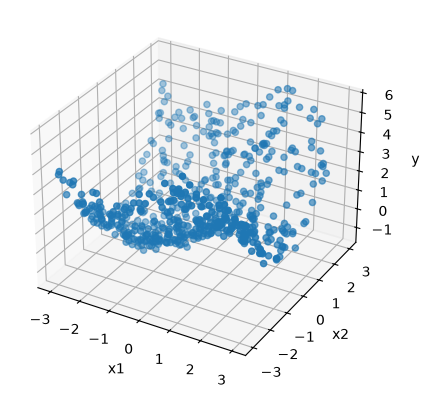

In [35]:
fig = plt.figure()
ax = fig.add_subplot(projection="3d")
ax.scatter(X_train[:, 0], X_train[:, 1], zs=y_train)
ax.set(xlabel="x1", ylabel="x2", zlabel="y")

### Part (b)

We fit the dataset using ridge regression.

In [37]:
X_val = ds.val.X
y_val = ds.val.y

In [43]:
RKS = RandomKitchenSinks()
best_model, best_val_mse, best_D, scores = \
    sweep_rks_model([1,2,4,8,10,12,15,20,25], X_train, y_train, X_val, y_val)
print(scores)

[(1, np.float64(2.463327201120436), np.float64(2.396572045225377)), (2, np.float64(2.0897602609684123), np.float64(1.8851093033473476)), (4, np.float64(2.413010349608702), np.float64(2.335904540393924)), (8, np.float64(0.6318564530302538), np.float64(0.6345586298579196)), (10, np.float64(0.29205771913638795), np.float64(0.3330664043920113)), (12, np.float64(0.20902408487017707), np.float64(0.18919549089650153)), (15, np.float64(0.03457956722756639), np.float64(0.03713915946206881)), (20, np.float64(0.6450795496444327), np.float64(0.5131753527379084)), (25, np.float64(0.1938953515376406), np.float64(0.16886515983984018))]


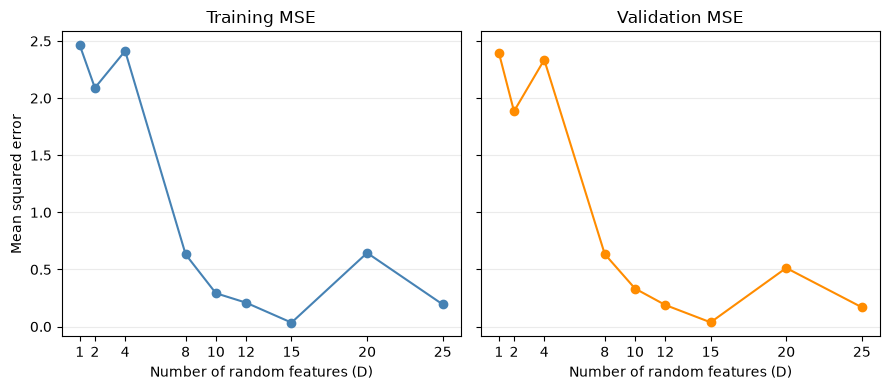

In [44]:
D_values, train_mse, val_mse = zip(*scores)

fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharey=True)
for ax, mse, title, color in zip(
    axes, [train_mse, val_mse], ["Training", "Validation"], ["steelblue", "darkorange"]
):
    ax.plot(D_values, mse, marker="o", color=color)
    ax.set(title=f"{title} MSE", xlabel="Number of random features (D)", xticks=D_values)
    ax.grid(axis="y", alpha=0.25)

axes[0].set_ylabel("Mean squared error")
fig.tight_layout()
plt.show()

In [46]:
best_model.D

15

### Part (c)

In [50]:
best_model, best_val_mse, best_lr, scores = \
    mlp_sweep([0.001, 0.01, 0.03, 0.1], X_train, y_train, X_val, y_val)
print(scores)

Epoch 1/20, Loss: 4.4204
Epoch 2/20, Loss: 3.0019
Epoch 3/20, Loss: 2.2508
Epoch 4/20, Loss: 1.8433
Epoch 5/20, Loss: 1.6128
Epoch 6/20, Loss: 1.4759
Epoch 7/20, Loss: 1.3908
Epoch 8/20, Loss: 1.3313
Epoch 9/20, Loss: 1.2891
Epoch 10/20, Loss: 1.2547
Epoch 11/20, Loss: 1.2281
Epoch 12/20, Loss: 1.2037
Epoch 13/20, Loss: 1.1825
Epoch 14/20, Loss: 1.1618
Epoch 15/20, Loss: 1.1419
Epoch 16/20, Loss: 1.1250
Epoch 17/20, Loss: 1.1076
Epoch 18/20, Loss: 1.0926
Epoch 19/20, Loss: 1.0769
Epoch 20/20, Loss: 1.0605
Epoch 1/20, Loss: 2.7488
Epoch 2/20, Loss: 1.3415
Epoch 3/20, Loss: 1.1227
Epoch 4/20, Loss: 0.9433
Epoch 5/20, Loss: 0.8075
Epoch 6/20, Loss: 0.7030
Epoch 7/20, Loss: 0.6114
Epoch 8/20, Loss: 0.5373
Epoch 9/20, Loss: 0.4835
Epoch 10/20, Loss: 0.4371
Epoch 11/20, Loss: 0.3953
Epoch 12/20, Loss: 0.3668
Epoch 13/20, Loss: 0.3417
Epoch 14/20, Loss: 0.3233
Epoch 15/20, Loss: 0.3051
Epoch 16/20, Loss: 0.2903
Epoch 17/20, Loss: 0.2789
Epoch 18/20, Loss: 0.2679
Epoch 19/20, Loss: 0.2588
Epoc

In [51]:
import numpy as np
from models import mlp_sweep

learning_rates = [0.001, 0.01, 0.03, 0.1]
best_mlp, best_mlp_val_mse, best_lr, mlp_scores = mlp_sweep(
    learning_rates, X_train, y_train, X_val, y_val
)

for lr, train_mse, val_mse in mlp_scores:
    print(f"lr={lr:g} | train MSE={train_mse:.4f} | validation MSE={val_mse:.4f}")
if best_mlp is not None:
    print(f"Best learning rate: {best_lr:g}, validation MSE: {best_mlp_val_mse:.4f}")
else:
    print("No run produced a finite validation MSE.")

Epoch 1/20, Loss: 4.4204
Epoch 2/20, Loss: 3.0019
Epoch 3/20, Loss: 2.2508
Epoch 4/20, Loss: 1.8433
Epoch 5/20, Loss: 1.6128
Epoch 6/20, Loss: 1.4759
Epoch 7/20, Loss: 1.3908
Epoch 8/20, Loss: 1.3313
Epoch 9/20, Loss: 1.2891
Epoch 10/20, Loss: 1.2547
Epoch 11/20, Loss: 1.2281
Epoch 12/20, Loss: 1.2037
Epoch 13/20, Loss: 1.1825
Epoch 14/20, Loss: 1.1618
Epoch 15/20, Loss: 1.1419
Epoch 16/20, Loss: 1.1250
Epoch 17/20, Loss: 1.1076
Epoch 18/20, Loss: 1.0926
Epoch 19/20, Loss: 1.0769
Epoch 20/20, Loss: 1.0605
Epoch 1/20, Loss: 2.7488
Epoch 2/20, Loss: 1.3415
Epoch 3/20, Loss: 1.1227
Epoch 4/20, Loss: 0.9433
Epoch 5/20, Loss: 0.8075
Epoch 6/20, Loss: 0.7030
Epoch 7/20, Loss: 0.6114
Epoch 8/20, Loss: 0.5373
Epoch 9/20, Loss: 0.4835
Epoch 10/20, Loss: 0.4371
Epoch 11/20, Loss: 0.3953
Epoch 12/20, Loss: 0.3668
Epoch 13/20, Loss: 0.3417
Epoch 14/20, Loss: 0.3233
Epoch 15/20, Loss: 0.3051
Epoch 16/20, Loss: 0.2903
Epoch 17/20, Loss: 0.2789
Epoch 18/20, Loss: 0.2679
Epoch 19/20, Loss: 0.2588
Epoc

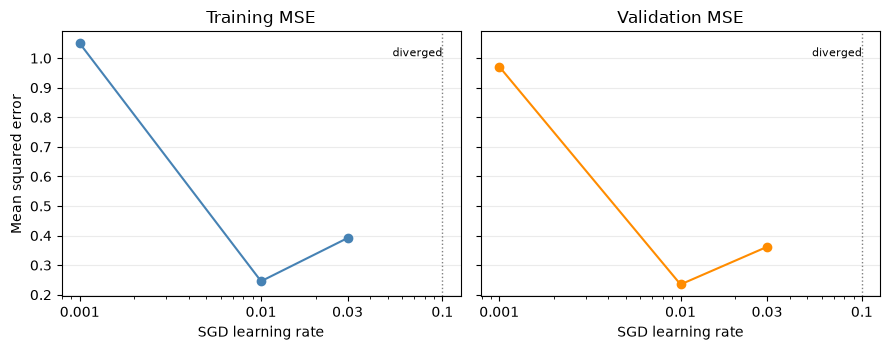

In [52]:
import matplotlib.pyplot as plt

lr_values, train_losses, val_losses = np.array(mlp_scores).T
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
for ax, losses, label, color in zip(axes, [train_losses, val_losses],["Training", "Validation"], ["steelblue", "darkorange"]):
    finite = np.isfinite(losses)
    ax.plot(lr_values[finite], losses[finite], "o-", color=color)
    for rate in lr_values[~finite]:
        ax.axvline(rate, color="gray", ls=":", lw=1)
        ax.text(rate, 0.94, "diverged", transform=ax.get_xaxis_transform(),
                ha="right", va="top", fontsize=8)
    ax.set_xscale("log")
    ax.set_xticks(lr_values, labels=[str(rate) for rate in lr_values])
    ax.set(xlabel="SGD learning rate", title=f"{label} MSE")
    ax.grid(axis="y", alpha=0.25)
axes[0].set_ylabel("Mean squared error")
fig.tight_layout()
plt.show()

### Part (d)

So the best-performing hyperparameters from the previous steps are: 
- D = 15 for Random Kitchen Sink Regressor.
- lr = 0.01 for MLP. \
We will fit them and report the validation loss for each.

In [67]:
from models import MLP as MLPRegressor

Instantiate the models with the above hyperparameters.

In [68]:
rks_final = RandomKitchenSinks(D=2 * (best_D // 2))
mlp_final = MLPRegressor(d_in=X_train.shape[1], lr=best_lr)

In [69]:
rks_final.fit(X_train, y_train)
mlp_final.fit(X_train, y_train)

Epoch 1/20, Loss: 2.2968
Epoch 2/20, Loss: 1.1702
Epoch 3/20, Loss: 0.9914
Epoch 4/20, Loss: 0.8459
Epoch 5/20, Loss: 0.7360
Epoch 6/20, Loss: 0.6460
Epoch 7/20, Loss: 0.5760
Epoch 8/20, Loss: 0.5141
Epoch 9/20, Loss: 0.4643
Epoch 10/20, Loss: 0.4283
Epoch 11/20, Loss: 0.3962
Epoch 12/20, Loss: 0.3773
Epoch 13/20, Loss: 0.3481
Epoch 14/20, Loss: 0.3284
Epoch 15/20, Loss: 0.3100
Epoch 16/20, Loss: 0.3002
Epoch 17/20, Loss: 0.2855
Epoch 18/20, Loss: 0.2736
Epoch 19/20, Loss: 0.2659
Epoch 20/20, Loss: 0.2560


In [70]:
from sklearn.metrics import mean_squared_error

In [73]:
pred_val_rks = rks_final.predict(X_val)
pred_val_mlp = mlp_final.predict(X_val)
loss_val_rks = mean_squared_error(y_val, pred_val_rks)
loss_val_mlp = mean_squared_error(y_val, pred_val_mlp)

In [74]:
print(f"Validation loss of Ridge : {loss_val_rks}, Validation loss of MLP : {loss_val_mlp}")

Validation loss of Ridge : 0.37049192944859904, Validation loss of MLP : 0.24454864339741988


In [75]:
import numpy as np

X_test = ds.test.X
for name, fitted in [("rks", rks_final), ("mlp", mlp_final)]:
    preds = np.asarray(fitted.predict(X_test)).reshape(-1)
    assert preds.size == len(X_test) and np.isfinite(preds).all()
    filename = f"{name}_test_predictions.csv"
    np.savetxt(filename, preds, delimiter=",", fmt="%.17g")
    np.testing.assert_array_equal(np.loadtxt(filename, delimiter=","), preds)
    print(f"{filename}: {len(preds)} rows")

rks_test_predictions.csv: 200 rows
mlp_test_predictions.csv: 200 rows


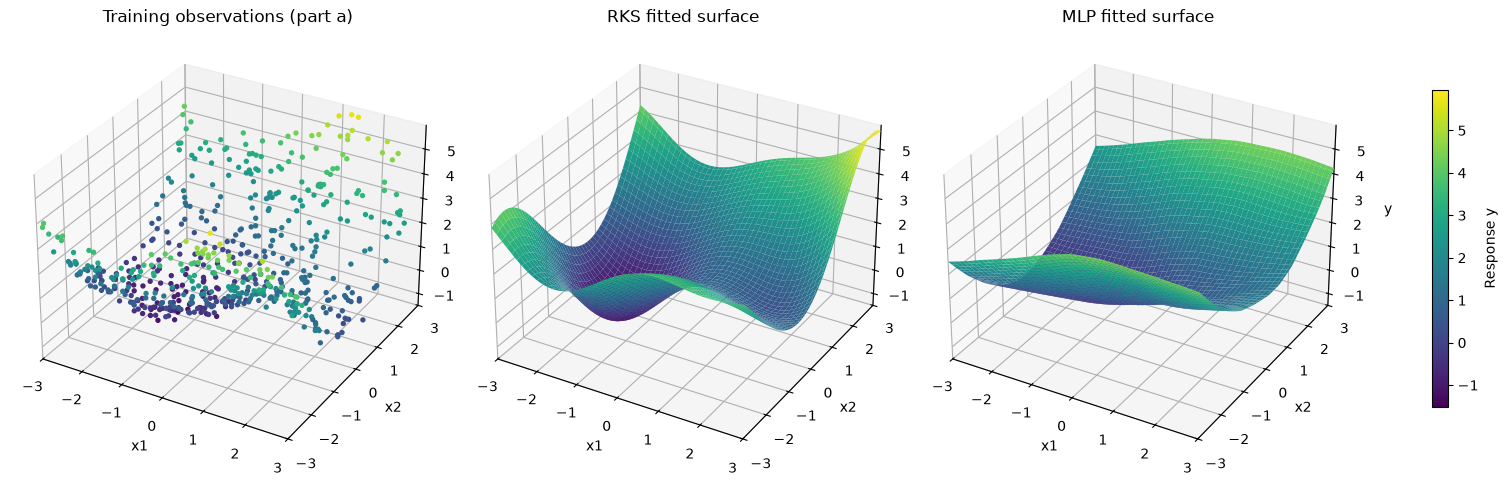

In [78]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

def surface_grid(predict, xlim=(-3, 3), ylim=(-3, 3), grid=100):
    xs = np.linspace(*xlim, grid)
    ys = np.linspace(*ylim, grid)
    X1, X2 = np.meshgrid(xs, ys)
    Xgrid = np.stack([X1.ravel(), X2.ravel()], axis=1)
    Z = np.asarray(predict(Xgrid)).reshape(X1.shape)
    return X1, X2, Z

surfaces = [surface_grid(rks_final.predict), surface_grid(mlp_final.predict)]
values = np.concatenate([y_train.ravel()] + [Z.ravel() for _, _, Z in surfaces])
norm = Normalize(values.min(), values.max())

fig, axes = plt.subplots(1, 3, figsize=(15, 5), subplot_kw={"projection": "3d"},
                         constrained_layout=True)
points = axes[0].scatter(X_train[:, 0], X_train[:, 1], y_train,
                         c=y_train, cmap="viridis", norm=norm, s=8, depthshade=False)
axes[0].set_title("Training observations (part a)")
for ax, (X1, X2, Z), name in zip(axes[1:], surfaces, ["RKS", "MLP"]):
    ax.plot_surface(X1, X2, Z, cmap="viridis", norm=norm, linewidth=0)
    ax.set_title(f"{name} fitted surface")

for ax in axes:
    ax.set(xlabel="x1", ylabel="x2", zlabel="y", xlim=(-3, 3), ylim=(-3, 3),
           zlim=(values.min(), values.max()))
    ax.view_init(elev=30, azim=-60)
fig.colorbar(points, ax=axes, label="Response y", shrink=0.65)
fig.savefig("q3d_surfaces_3d.png", dpi=200, bbox_inches="tight")
plt.show()

In part a, we observed that the y values trough near the center along the second input, and these values increase with respect to |x2|. Both the RKS model and the MLP model captures this trough pretty good.
That is expected, as random kitchen sink technique was proven to be succesful in capturing non-linear relationships, \ the feature directions and frequencies are sampled before fitting. The MLP achieved a lower validation MSE than the RKS model. One explanation is that the MLP learned where the slope of the surface must change, while the RKS model had feature directions and frequencies sampled before training.